# ????? ???? ????? ???????

???? ??? ?????? ?? ????? ????? ????????? ??????? ???????? ????????? ???????? ??????? ?????? ?????. ????? ????? ?????? ?? `data/raw/` ???? ?? ???? ?? ?????? ?? ??????? ??? ??? ??????. ?? ????? `test.csv` ??? `num_orders`? ???? ?????? ??? 10 ?????? ?????? ?? `train.csv` ?????? ?? ????????? ?? ?????? `test.csv` ?????? ??? ?????? ???????.

??????? ???? ?????: ???????? Mann?Whitney ?Spearman ?? ???? ???????. ???? ??????? ?? ?????? ?????? ??????? ???????? ???????? ??????? ??????? ?? ????? ??????.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / 'data' / 'raw' / 'train.csv').exists():
            return candidate
    raise FileNotFoundError('Could not find data/raw/train.csv from the notebook working directory.')

ROOT = find_project_root(Path.cwd())
RAW = ROOT / 'data' / 'raw'
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)

def audit(frame: pd.DataFrame, label: str) -> None:
    if 'num_orders' in frame:
        order_total = f" | num_orders sum: {frame['num_orders'].sum():,.0f}"
    elif 'total_orders' in frame:
        order_total = f" | total_orders sum: {frame['total_orders'].sum():,.0f}"
    else:
        order_total = ''
    print(f'{label}: rows={len(frame):,}, columns={frame.shape[1]}{order_total}')

train = pd.read_csv(RAW / 'train.csv')
centers = pd.read_csv(RAW / 'fulfilment_center_info.csv')
meals = pd.read_csv(RAW / 'meal_info.csv')
test_path = RAW / 'test.csv'
test = pd.read_csv(test_path) if test_path.exists() else None

for name, frame in [('train.csv', train), ('fulfilment_center_info.csv', centers), ('meal_info.csv', meals)]:
    audit(frame, name)
    print('columns:', frame.columns.tolist())
    missing = frame.isna().sum()
    print('missing values:', missing[missing.gt(0)].to_dict() or 'none')
if test is not None:
    audit(test, 'test.csv (reserved; no target column)')

print('Duplicate train ids:', train['id'].duplicated().sum())
print('Duplicate train (week, center_id, meal_id) keys:', train.duplicated(['week', 'center_id', 'meal_id']).sum())
print('Duplicate center_id lookup keys:', centers['center_id'].duplicated().sum())
print('Duplicate meal_id lookup keys:', meals['meal_id'].duplicated().sum())

train.csv: rows=456,548, columns=9 | num_orders sum: 119,557,485
columns: ['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']
missing values: none
fulfilment_center_info.csv: rows=77, columns=5
columns: ['center_id', 'city_code', 'region_code', 'center_type', 'op_area']
missing values: none
meal_info.csv: rows=51, columns=3
columns: ['meal_id', 'category', 'cuisine']
missing values: none
test.csv (reserved; no target column): rows=32,573, columns=8
Duplicate train ids: 0
Duplicate train (week, center_id, meal_id) keys: 0
Duplicate center_id lookup keys: 0
Duplicate meal_id lookup keys: 0


## ربط البيانات والتحقق

نستخدم ربطاً يسارياً مع التحقق من أن مفاتيح الجداول الوصفية فريدة (`many_to_one`). تُطبع أعداد الصفوف والأعمدة ومجموع الطلبات قبل كل ربط وبعده؛ أي تغيّر في عدد السجلات أو مجموع الطلبات يحتاج إلى تفسير قبل متابعة التحليل.

In [2]:
orders = train.copy()
audit(orders, 'Before center join')
orders = orders.merge(centers, on='center_id', how='left', validate='many_to_one', indicator='_center_merge')
audit(orders, 'After center join')
print('Unmatched centers:', int(orders['_center_merge'].eq('left_only').sum()))
orders = orders.drop(columns='_center_merge')
audit(orders, 'After removing center-join diagnostic column')

audit(orders, 'Before meal join')
orders = orders.merge(meals, on='meal_id', how='left', validate='many_to_one', indicator='_meal_merge')
audit(orders, 'After meal join')
print('Unmatched meals:', int(orders['_meal_merge'].eq('left_only').sum()))
orders = orders.drop(columns='_meal_merge')
audit(orders, 'After removing meal-join diagnostic column')

assert len(orders) == len(train), 'A lookup join changed the number of order rows.'
assert orders['num_orders'].sum() == train['num_orders'].sum(), 'A lookup join changed total orders.'
assert not orders[['center_type', 'op_area', 'category', 'cuisine']].isna().any().any(), 'Unmatched lookup data requires investigation.'
print('Join validation passed: row count and order total are unchanged.')

Before center join: rows=456,548, columns=9 | num_orders sum: 119,557,485
After center join: rows=456,548, columns=14 | num_orders sum: 119,557,485
Unmatched centers: 0
After removing center-join diagnostic column: rows=456,548, columns=13 | num_orders sum: 119,557,485
Before meal join: rows=456,548, columns=13 | num_orders sum: 119,557,485
After meal join: rows=456,548, columns=16 | num_orders sum: 119,557,485
Unmatched meals: 0
After removing meal-join diagnostic column: rows=456,548, columns=15 | num_orders sum: 119,557,485
Join validation passed: row count and order total are unchanged.


## فحص الجودة وقرارات التنظيف

نقيس المشكلات المحتملة أولاً قبل حذف أي سجل. لا يُحذف أي صف لمجرد كونه متطرفاً؛ فالطلب المرتفع قد يكون طلباً حقيقياً. إذا أضيف تنظيف لاحقاً، يجب توثيق السبب وطباعة الصفوف والأعمدة ومجموع الطلبات قبل العملية وبعدها.

In [3]:
audit(orders, 'Joined data before quality review')
print('Missing values by column:', orders.isna().sum()[orders.isna().sum().gt(0)].to_dict() or 'none')
print('Duplicate business keys (week, center_id, meal_id):', int(orders.duplicated(['week', 'center_id', 'meal_id']).sum()))
print('Rows with checkout_price > base_price:', int(orders['checkout_price'].gt(orders['base_price']).sum()))
print('Rows with non-positive prices:', int((orders[['checkout_price', 'base_price']] <= 0).any(axis=1).sum()))
print('Rows with negative orders:', int(orders['num_orders'].lt(0).sum()))

q1, q3 = orders['num_orders'].quantile([0.25, 0.75])
iqr = q3 - q1
outlier_mask = orders['num_orders'].lt(q1 - 1.5 * iqr) | orders['num_orders'].gt(q3 + 1.5 * iqr)
print('IQR-flagged order rows (review, not automatically removed):', int(outlier_mask.sum()))

all_weeks = set(range(int(orders['week'].min()), int(orders['week'].max()) + 1))
week_coverage = orders.groupby(['center_id', 'meal_id'])['week'].agg(lambda values: len(all_weeks - set(values)))
print('Center-meal series with missing weeks:', int(week_coverage.gt(0).sum()))
print('Total missing center-meal weeks:', int(week_coverage.sum()))

# No records are dropped at this stage: anomalies are retained until investigated.
analysis = orders.copy()
audit(analysis, 'Analysis data after documented no-drop cleaning decision')

Joined data before quality review: rows=456,548, columns=15 | num_orders sum: 119,557,485
Missing values by column: none
Duplicate business keys (week, center_id, meal_id): 0
Rows with checkout_price > base_price: 116101
Rows with non-positive prices: 0
Rows with negative orders: 0
IQR-flagged order rows (review, not automatically removed): 32937
Center-meal series with missing weeks: 2350
Total missing center-meal weeks: 65017
Analysis data after documented no-drop cleaning decision: rows=456,548, columns=15 | num_orders sum: 119,557,485


## مؤشرات الطلب والتذبذب

الإيراد التقديري هنا يساوي سعر الدفع مضروباً في الطلبات المسجلة. الخصم النسبي يُحسب مقابل `base_price` عندما يكون السعر الأساسي موجباً. أرقام هذا القسم تُستخرج مباشرة من الجداول المعروضة ويمكن الاستشهاد بها في التقرير.

In [4]:
audit(analysis, 'Analysis data before KPI calculations')
analysis = analysis.assign(
    estimated_revenue=analysis['checkout_price'] * analysis['num_orders'],
    discount_pct=np.where(
        analysis['base_price'] > 0,
        (analysis['base_price'] - analysis['checkout_price']) / analysis['base_price'] * 100,
        np.nan,
    ),
)
audit(analysis, 'Analysis data after adding revenue and discount columns')

weekly = analysis.groupby('week', as_index=False)['num_orders'].sum().sort_values('week')
total_orders = int(analysis['num_orders'].sum())
mean_weekly_orders = weekly['num_orders'].mean()
estimated_revenue = analysis['estimated_revenue'].sum()
valid_discount_rows = analysis['discount_pct'].notna().sum()
mean_discount_pct = analysis['discount_pct'].mean()
print(f'Total orders: {total_orders:,}')
print(f'Observed weeks: {len(weekly):,}')
print(f'Mean weekly orders: {mean_weekly_orders:,.2f}')
print(f'Estimated revenue (checkout_price x num_orders; not profit): {estimated_revenue:,.2f}')
print(f'Mean relative discount/price change: {mean_discount_pct:.2f}% across {valid_discount_rows:,} rows with base_price > 0')
print(f'Rows with email promotion: {analysis["emailer_for_promotion"].eq(1).mean():.2%}')
print(f'Rows with homepage feature: {analysis["homepage_featured"].eq(1).mean():.2%}')

category_demand = analysis.groupby('category', as_index=False)['num_orders'].sum().sort_values('num_orders', ascending=False)
category_demand['cumulative_share'] = category_demand['num_orders'].cumsum() / total_orders
category_cutoff = int(np.flatnonzero(category_demand['cumulative_share'].ge(0.8))[0])
top_80_categories = category_demand.iloc[:category_cutoff + 1].copy()

meal_demand = analysis.groupby(['meal_id', 'category', 'cuisine'], as_index=False)['num_orders'].sum().sort_values('num_orders', ascending=False)
meal_demand['cumulative_share'] = meal_demand['num_orders'].cumsum() / total_orders
meal_cutoff = int(np.flatnonzero(meal_demand['cumulative_share'].ge(0.8))[0])
top_80_meals = meal_demand.iloc[:meal_cutoff + 1].copy()

center_week = analysis.groupby(['center_type', 'center_id', 'week'], as_index=False)['num_orders'].sum()
center_week_average = center_week.groupby(['center_type', 'center_id'], as_index=False)['num_orders'].mean().rename(columns={'num_orders': 'mean_weekly_orders_per_center'})
center_type_demand = center_week_average.groupby('center_type', as_index=False).agg(
    mean_weekly_orders_per_center=('mean_weekly_orders_per_center', 'mean'),
    median_weekly_orders_per_center=('mean_weekly_orders_per_center', 'median'),
    centers=('center_id', 'nunique'),
)
center_type_total = analysis.groupby('center_type', as_index=False)['num_orders'].sum().rename(columns={'num_orders': 'total_orders'})
audit(center_type_demand, 'Center-type summary before total-orders join')
center_type_demand = center_type_demand.merge(center_type_total, on='center_type', how='left', validate='one_to_one')
audit(center_type_demand, 'Center-type summary after total-orders join')

# Per-meal CV uses observed meal-week totals summed over centers; absent weeks are not filled with zero.
meal_weekly = analysis.groupby(['meal_id', 'week'], as_index=False)['num_orders'].sum()
meal_variability = meal_weekly.groupby('meal_id', as_index=False).agg(
    mean_weekly_orders=('num_orders', 'mean'),
    std_weekly_orders=('num_orders', 'std'),
    total_orders=('num_orders', 'sum'),
    observed_weeks=('week', 'nunique'),
)
meal_variability = meal_variability.merge(meals, on='meal_id', how='left', validate='many_to_one')
meal_variability['cv'] = meal_variability['std_weekly_orders'] / meal_variability['mean_weekly_orders'].replace(0, np.nan)
meal_variability['cv_rank_pct'] = meal_variability['cv'].rank(pct=True)
meal_variability['volume_rank_pct'] = meal_variability['total_orders'].rank(pct=True)
meal_variability['joint_demand_risk_score'] = (meal_variability['cv_rank_pct'] + meal_variability['volume_rank_pct']) / 2
joint_demand_ranking = meal_variability.sort_values('joint_demand_risk_score', ascending=False)

# Retain center-meal series CV for the existing diagnostic chart, without imputing missing weeks.
center_meal_weekly = analysis.groupby(['center_id', 'meal_id', 'week'], as_index=False)['num_orders'].sum()
center_meal_variability = center_meal_weekly.groupby(['center_id', 'meal_id'], as_index=False).agg(
    mean_weekly_orders=('num_orders', 'mean'),
    std_weekly_orders=('num_orders', 'std'),
    series_total_orders=('num_orders', 'sum'),
)
center_meal_variability['cv'] = center_meal_variability['std_weekly_orders'] / center_meal_variability['mean_weekly_orders'].replace(0, np.nan)

print('80% cutoff category included:', top_80_categories.iloc[-1]['category'], f"(cumulative share={top_80_categories.iloc[-1]['cumulative_share']:.2%})")
print('80% cutoff meal included:', int(top_80_meals.iloc[-1]['meal_id']), f"(cumulative share={top_80_meals.iloc[-1]['cumulative_share']:.2%})")
print('Joint ranking: average percentile rank of CV and total observed orders; higher means both are relatively high.')
display(weekly, category_demand, top_80_categories, top_80_meals, center_type_demand, meal_variability.sort_values('cv', ascending=False).head(15), joint_demand_ranking.head(15))

Analysis data before KPI calculations: rows=456,548, columns=15 | num_orders sum: 119,557,485
Analysis data after adding revenue and discount columns: rows=456,548, columns=17 | num_orders sum: 119,557,485
Total orders: 119,557,485
Observed weeks: 145
Mean weekly orders: 824,534.38
Estimated revenue (checkout_price x num_orders; not profit): 31,922,771,040.11
Mean relative discount/price change: 5.72% across 456,548 rows with base_price > 0
Rows with email promotion: 8.12%
Rows with homepage feature: 10.92%
Center-type summary before total-orders join: rows=3, columns=4
Center-type summary after total-orders join: rows=3, columns=5 | total_orders sum: 119,557,485
80% cutoff category included: Pizza (cumulative share=81.40%)
80% cutoff meal included: 1558 (cumulative share=81.18%)
Joint ranking: average percentile rank of CV and total observed orders; higher means both are relatively high.


,week,num_orders
0,1,792261
1,2,787084
2,3,695262
3,4,743529
4,5,1198675
...,...,...
140,141,776240
141,142,739661
142,143,759926
143,144,801197


,category,num_orders,cumulative_share
0,Beverages,40480525,0.338586
8,Rice Bowl,20874063,0.513181
10,Sandwich,17636782,0.660698
9,Salad,10944336,0.752238
7,Pizza,7383720,0.813997
5,Other Snacks,4766293,0.853863
13,Starters,4649122,0.892749
3,Extras,3984979,0.926080
11,Seafood,2715714,0.948795
2,Desert,1940754,0.965028


,category,num_orders,cumulative_share
0,Beverages,40480525,0.338586
8,Rice Bowl,20874063,0.513181
10,Sandwich,17636782,0.660698
9,Salad,10944336,0.752238
7,Pizza,7383720,0.813997


,meal_id,category,cuisine,num_orders,cumulative_share
30,2290,Rice Bowl,Indian,9770303,0.081721
22,1885,Beverages,Thai,8346246,0.151530
16,1754,Sandwich,Italian,6818059,0.208557
26,1993,Beverages,Thai,6656856,0.264237
1,1109,Rice Bowl,Indian,6367773,0.317498
46,2707,Beverages,Italian,5932792,0.367121
25,1971,Sandwich,Italian,5728620,0.415036
48,2826,Sandwich,Italian,5090103,0.457610
15,1727,Rice Bowl,Indian,4735987,0.497223
0,1062,Beverages,Italian,4712795,0.536642


,center_type,mean_weekly_orders_per_center,median_weekly_orders_per_center,centers,total_orders
0,TYPE_A,11063.114194,10007.213793,43,68978517
1,TYPE_B,13982.632701,13148.517241,15,29996073
2,TYPE_C,7471.105263,7006.344828,19,20582895


,meal_id,mean_weekly_orders,std_weekly_orders,total_orders,observed_weeks,category,cuisine,cv,cv_rank_pct,volume_rank_pct,joint_demand_risk_score
34,2444,6500.468966,7833.130305,942568,145,Seafood,Continental,1.205010,1.000000,0.372549,0.686275
25,1971,39507.724138,43605.509263,5728620,145,Sandwich,Italian,1.103721,0.980392,0.882353,0.931373
10,1445,7304.972414,7986.194417,1059221,145,Seafood,Continental,1.093255,0.960784,0.431373,0.696078
49,2867,4923.620690,4953.652809,713925,145,Seafood,Continental,1.006100,0.941176,0.313725,0.627451
35,2490,29673.000000,27959.324242,3709125,125,Salad,Italian,0.942248,0.921569,0.784314,0.852941
30,2290,67381.400000,60641.916250,9770303,145,Rice Bowl,Indian,0.899980,0.901961,1.000000,0.950980
16,1754,47021.096552,41698.021104,6818059,145,Sandwich,Italian,0.886794,0.882353,0.960784,0.921569
27,2104,1838.586207,1513.660184,159957,87,Fish,Continental,0.823274,0.862745,0.019608,0.441176
15,1727,32661.979310,26274.639486,4735987,145,Rice Bowl,Indian,0.804441,0.843137,0.843137,0.843137
13,1558,12061.655172,9383.111367,1748940,145,Pizza,Continental,0.777929,0.823529,0.588235,0.705882


,meal_id,mean_weekly_orders,std_weekly_orders,total_orders,observed_weeks,category,cuisine,cv,cv_rank_pct,volume_rank_pct,joint_demand_risk_score
30,2290,67381.400000,60641.916250,9770303,145,Rice Bowl,Indian,0.899980,0.901961,1.000000,0.950980
25,1971,39507.724138,43605.509263,5728620,145,Sandwich,Italian,1.103721,0.980392,0.882353,0.931373
16,1754,47021.096552,41698.021104,6818059,145,Sandwich,Italian,0.886794,0.882353,0.960784,0.921569
35,2490,29673.000000,27959.324242,3709125,125,Salad,Italian,0.942248,0.921569,0.784314,0.852941
15,1727,32661.979310,26274.639486,4735987,145,Rice Bowl,Indian,0.804441,0.843137,0.843137,0.843137
1,1109,43915.675862,24620.199675,6367773,145,Rice Bowl,Indian,0.560624,0.705882,0.921569,0.813725
24,1962,22315.724138,15268.032510,3235780,145,Pizza,Continental,0.684183,0.764706,0.725490,0.745098
41,2581,16544.827586,11934.251022,2399000,145,Pizza,Continental,0.721328,0.784314,0.686275,0.735294
48,2826,35104.158621,17059.037946,5090103,145,Sandwich,Italian,0.485955,0.549020,0.862745,0.705882
13,1558,12061.655172,9383.111367,1748940,145,Pizza,Continental,0.777929,0.823529,0.588235,0.705882


## الاختبارات الإحصائية

يقارن اختبار Mann–Whitney الطلب مع الترويج وبدونه داخل كل مجموعة وجبة ومركز تتوفر فيها مشاهدتان على الأقل في كل حالة. يُعرض وسيط التغير النسبي بين الوسيطين، وتُصحح قيم p داخل كل نوع ترويج بطريقة Benjamini–Hochberg لكثرة الاختبارات. كما تُعرض نسبة السجلات ذات سعر أقل من السعر الأساسي حسب وجود الترويج، لأن العرض والخصم قد يجتمعان. اختبار Spearman يصف الارتباط الرتبي بين الخصم والطلب على مستوى الصفوف، ولا يعزل المركز أو الوجبة أو الأسبوع أو الترويج ولا يثبت السببية.

In [5]:
try:
    from scipy.stats import mannwhitneyu, spearmanr
except ImportError as exc:
    raise ImportError('Install scipy in the selected notebook environment to run the required statistical tests.') from exc

promotion_results = []
for flag in ['emailer_for_promotion', 'homepage_featured']:
    for (center_id, meal_id), group in analysis.groupby(['center_id', 'meal_id'], sort=False):
        no_promo = group.loc[group[flag].eq(0), 'num_orders']
        promo = group.loc[group[flag].eq(1), 'num_orders']
        if len(no_promo) >= 2 and len(promo) >= 2:
            test_result = mannwhitneyu(promo, no_promo, alternative='two-sided')
            baseline = no_promo.median()
            median_change_pct = ((promo.median() - baseline) / baseline * 100) if baseline > 0 else np.nan
            promotion_results.append({'promotion_flag': flag, 'center_id': center_id, 'meal_id': meal_id, 'n_promo': len(promo), 'n_no_promo': len(no_promo), 'median_orders_promo': promo.median(), 'median_orders_no_promo': baseline, 'median_change_pct': median_change_pct, 'u_statistic': test_result.statistic, 'p_value': test_result.pvalue})

promotion_tests = pd.DataFrame(promotion_results)
print('Eligible promotion-by-center-meal strata:', len(promotion_tests))
if not promotion_tests.empty:
    def benjamini_hochberg(p_values):
        p_values = np.asarray(p_values, dtype=float)
        order = np.argsort(p_values)
        ranked = p_values[order]
        adjusted = np.minimum.accumulate((ranked * len(ranked) / np.arange(1, len(ranked) + 1))[::-1])[::-1]
        result = np.empty_like(adjusted)
        result[order] = np.minimum(adjusted, 1.0)
        return result

    promotion_tests['q_value_bh'] = promotion_tests.groupby('promotion_flag')['p_value'].transform(benjamini_hochberg)
    promotion_summary = promotion_tests.groupby('promotion_flag').agg(
        eligible_center_meal_strata=('p_value', 'size'),
        median_within_stratum_change_pct=('median_change_pct', 'median'),
        strata_with_higher_median_orders=('median_change_pct', lambda values: int(values.gt(0).sum())),
        strata_with_lower_median_orders=('median_change_pct', lambda values: int(values.lt(0).sum())),
        unadjusted_p_below_005=('p_value', lambda values: int(values.lt(0.05).sum())),
        bh_q_below_005=('q_value_bh', lambda values: int(values.lt(0.05).sum())),
    ).reset_index()
    display(promotion_summary)
    display(promotion_tests.sort_values('q_value_bh').groupby('promotion_flag').head(10))

discount_promotion_context = []
for flag in ['emailer_for_promotion', 'homepage_featured']:
    for value, group in analysis.groupby(flag):
        discount_promotion_context.append({
            'promotion_flag': flag,
            'flag_value': int(value),
            'rows': len(group),
            'mean_relative_discount_pct': group['discount_pct'].mean(),
            'share_checkout_below_base_price': group['checkout_price'].lt(group['base_price']).mean(),
        })
discount_promotion_context = pd.DataFrame(discount_promotion_context)
display(discount_promotion_context)

spearman_data = analysis[['discount_pct', 'num_orders']].copy()
audit(spearman_data, 'Spearman rows before invalid-value cleanup')
spearman_data = spearman_data.replace([np.inf, -np.inf], np.nan)
audit(spearman_data, 'Spearman rows after replacing infinite values')
spearman_data = spearman_data.dropna()
audit(spearman_data, 'Spearman rows after dropping missing values')
spearman_result = spearmanr(spearman_data['discount_pct'], spearman_data['num_orders'])
p_display = f"{spearman_result.pvalue:.4g}" if spearman_result.pvalue > 0 else '<1e-300 (numerical underflow)'
print(f"Spearman rho={spearman_result.statistic:.4f}, p-value={p_display}, n={len(spearman_data):,}")

Eligible promotion-by-center-meal strata: 5612


,promotion_flag,eligible_center_meal_strata,median_within_stratum_change_pct,strata_with_higher_median_orders,strata_with_lower_median_orders,unadjusted_p_below_005,bh_q_below_005
0,emailer_for_promotion,2814,151.858762,2766,35,2380,2345
1,homepage_featured,2798,134.683236,2677,88,2350,2317


,promotion_flag,center_id,meal_id,n_promo,n_no_promo,median_orders_promo,median_orders_no_promo,median_change_pct,u_statistic,p_value,q_value_bh
4520,homepage_featured,30,1993,56,89,1323.5,649.0,103.929122,4929.0,4.360215e-23,1.219988e-19
5026,homepage_featured,23,1962,38,107,642.0,136.0,372.058824,3978.0,2.259054e-18,3.160416e-15
781,emailer_for_promotion,137,1962,40,105,844.0,257.0,228.404669,4036.5,1.080597e-17,4.024473e-15
1646,emailer_for_promotion,174,2581,40,105,641.5,190.0,237.631579,4044.0,8.083446e-18,4.024473e-15
1150,emailer_for_promotion,14,1962,40,104,580.5,122.0,375.819672,3999.0,1.144129e-17,4.024473e-15
1117,emailer_for_promotion,129,2581,42,102,215.0,68.0,216.176471,4096.0,8.701005e-18,4.024473e-15
602,emailer_for_promotion,99,2581,40,105,621.5,107.0,480.841121,4035.5,1.111042e-17,4.024473e-15
603,emailer_for_promotion,99,1962,40,105,892.0,150.0,494.666667,4062.5,3.949352e-18,4.024473e-15
2232,emailer_for_promotion,23,1962,40,105,634.0,136.0,366.176471,4066.5,3.376168e-18,4.024473e-15
179,emailer_for_promotion,13,1962,40,105,1350.0,433.0,211.778291,4046.5,7.345891e-18,4.024473e-15


,promotion_flag,flag_value,rows,mean_relative_discount_pct,share_checkout_below_base_price
0,emailer_for_promotion,0,419498,4.106837,0.462017
1,emailer_for_promotion,1,37050,23.978854,0.968205
2,homepage_featured,0,406693,4.374769,0.465636
3,homepage_featured,1,49855,16.689164,0.808665


Spearman rows before invalid-value cleanup: rows=456,548, columns=2 | num_orders sum: 119,557,485
Spearman rows after replacing infinite values: rows=456,548, columns=2 | num_orders sum: 119,557,485
Spearman rows after dropping missing values: rows=456,548, columns=2 | num_orders sum: 119,557,485
Spearman rho=0.1218, p-value=<1e-300 (numerical underflow), n=456,548


## الرسوم

الرسوم التالية محفوظة في `reports/figures/` ويمكن ربطها بنتائج الدفتر عند إعداد التقرير. عناوينها تصف المتغيرات المعروضة دون ادعاء علاقة سببية.

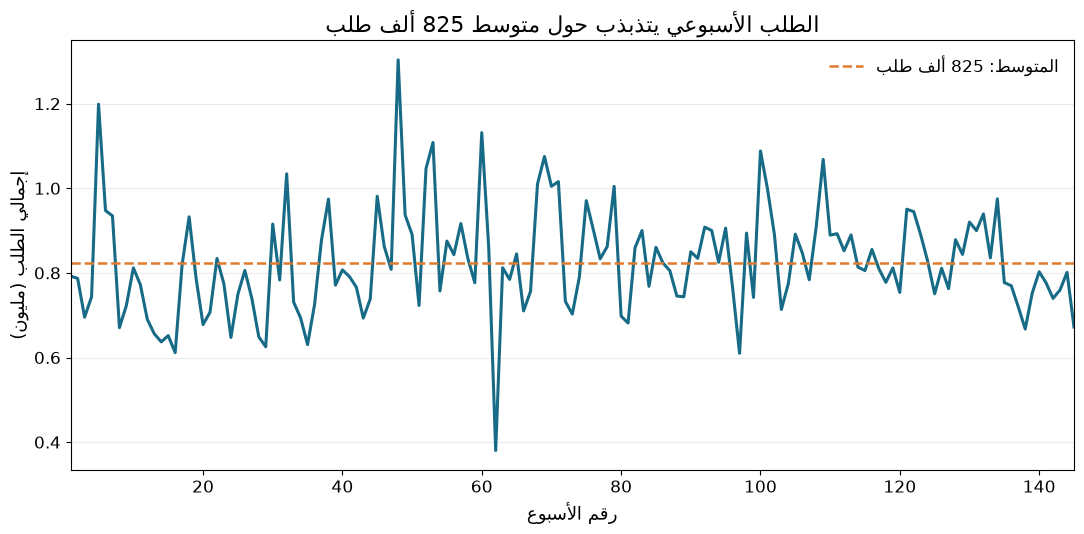

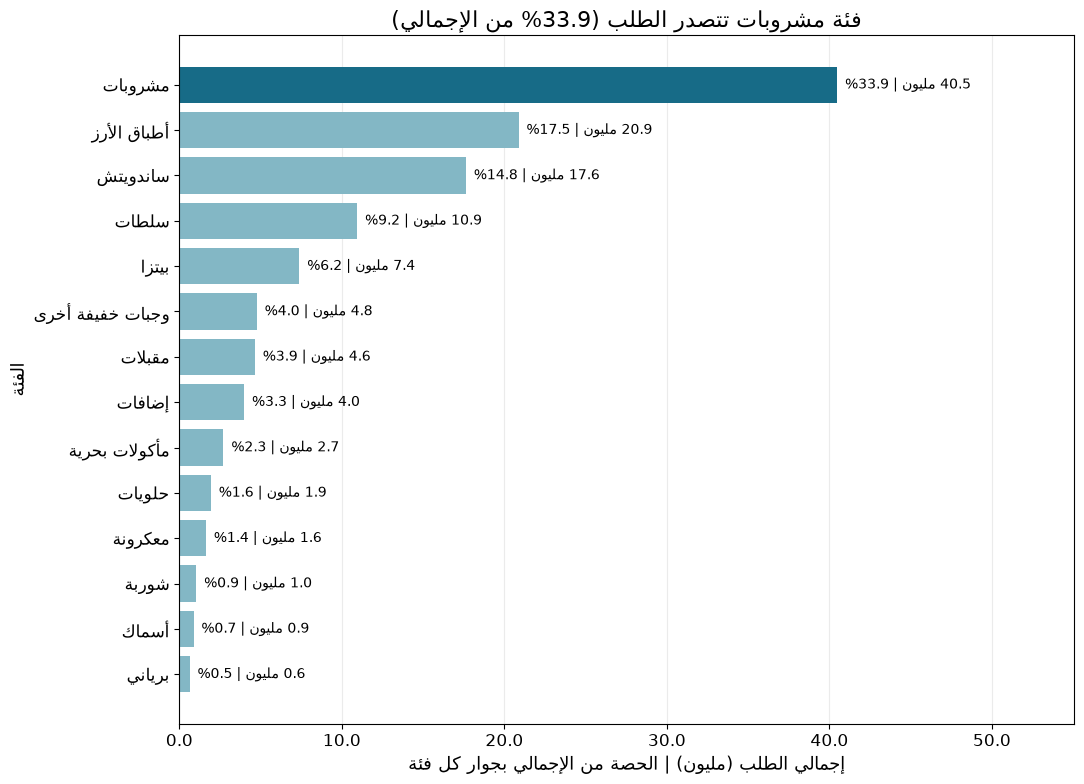

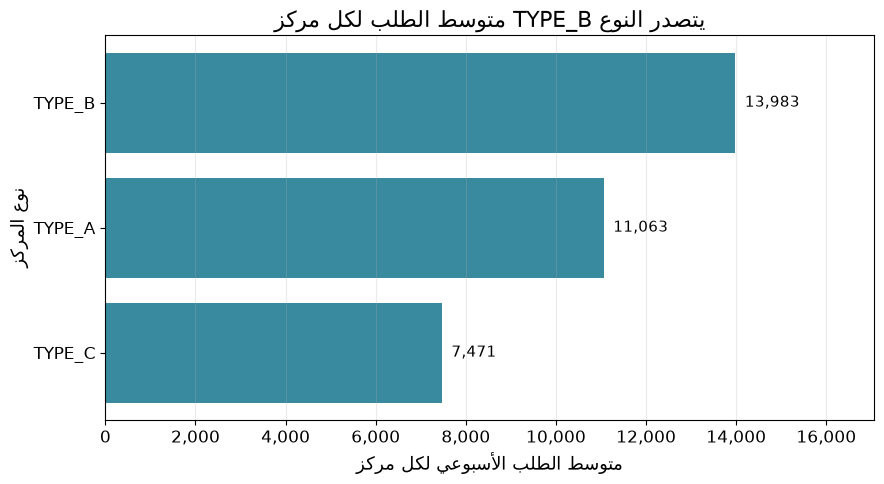

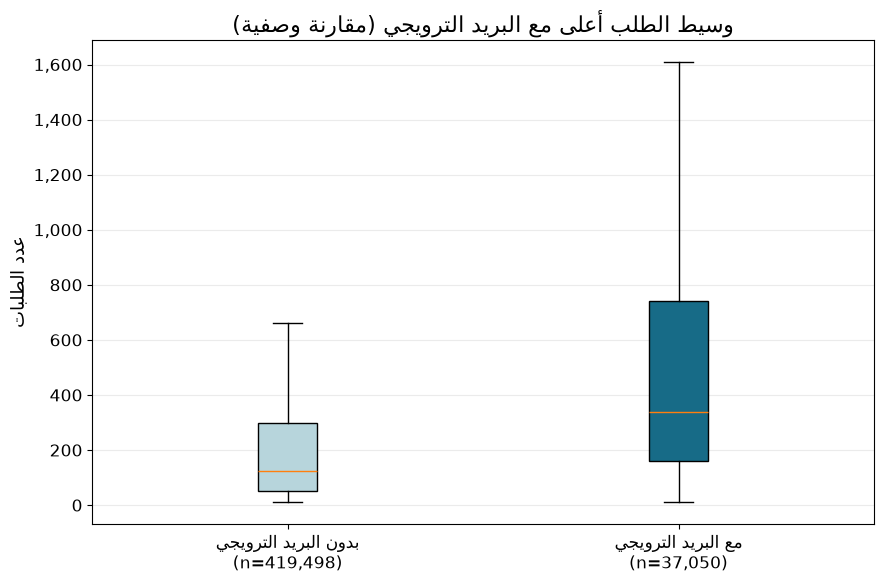

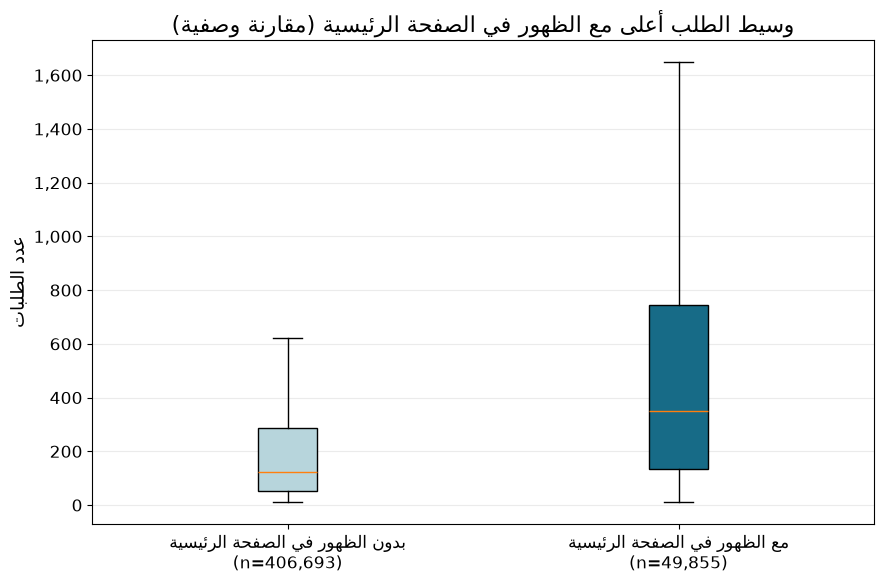

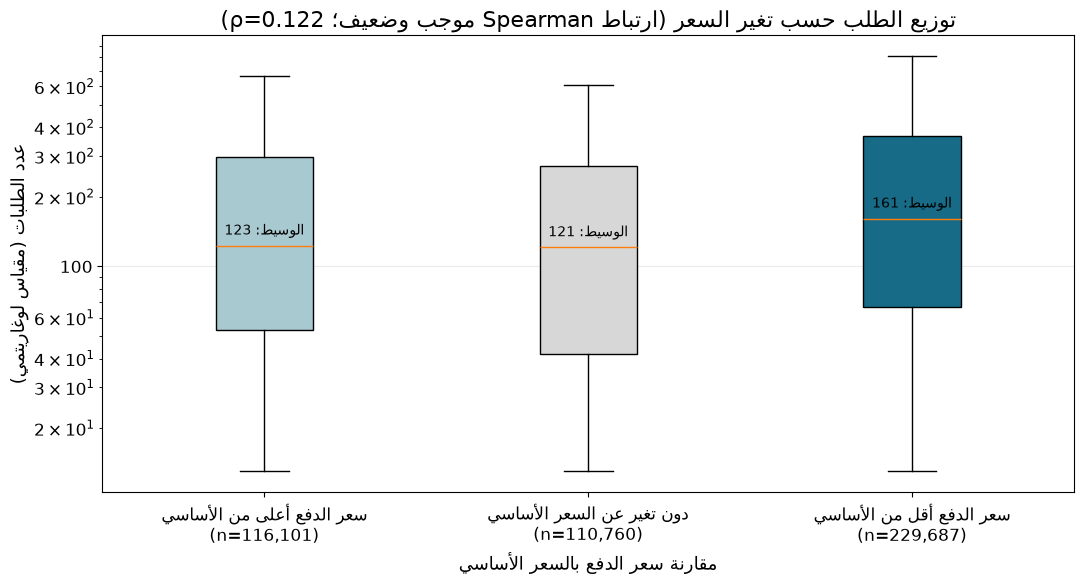

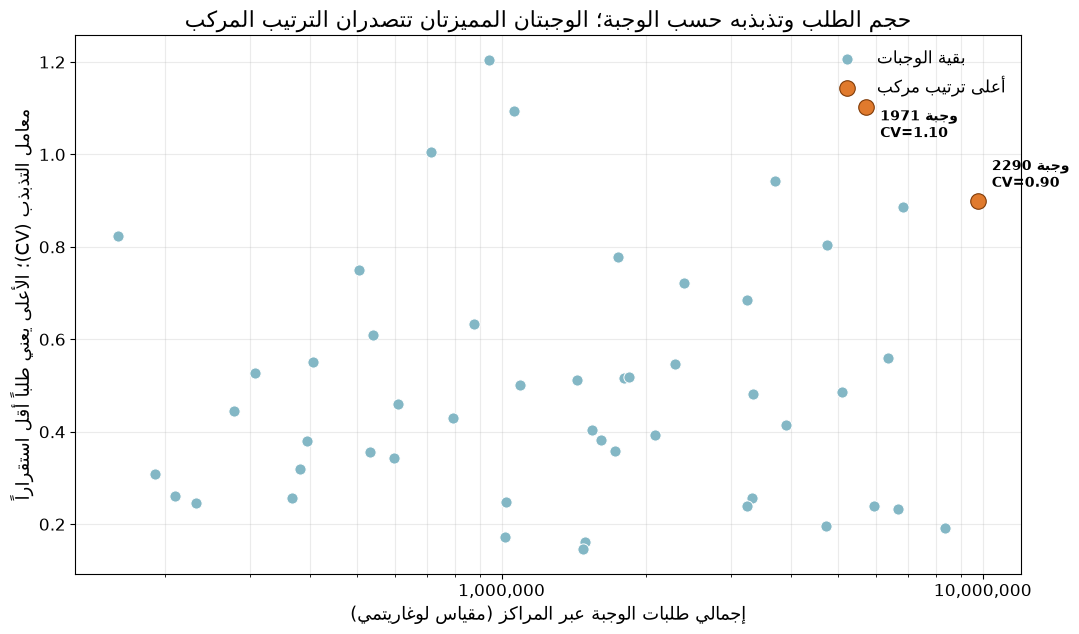

Saved PNG figures: ['category_demand.png', 'center_type_demand.png', 'demand_volume_vs_variability.png', 'discount_vs_orders.png', 'email_promotion_orders_boxplot.png', 'homepage_featured_orders_boxplot.png', 'weekly_demand.png']
Saved SVG figures: ['category_demand.svg', 'center_type_demand.svg', 'demand_volume_vs_variability.svg', 'discount_vs_orders.svg', 'email_promotion_orders_boxplot.svg', 'homepage_featured_orders_boxplot.svg', 'weekly_demand.svg']


In [7]:
from matplotlib.ticker import FuncFormatter

plt.rcParams.update({'font.size': 12, 'axes.titlesize': 16, 'axes.labelsize': 13})

def save_client_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.svg', bbox_inches='tight')
    fig.savefig(FIGURES / f'{name}.png', dpi=260, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)

million_formatter = FuncFormatter(lambda value, _: f'{value / 1_000_000:.1f}')

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(weekly['week'], weekly['num_orders'], color='#176B87', linewidth=2.2)
mean_weekly_for_chart = weekly['num_orders'].mean()
ax.axhline(mean_weekly_for_chart, color='#E07A2D', linestyle='--', linewidth=1.8, label=f'المتوسط: {mean_weekly_for_chart / 1_000:,.0f} ألف طلب')
ax.set_xlim(weekly['week'].min(), weekly['week'].max())
ax.yaxis.set_major_formatter(million_formatter)
ax.set(title=f'الطلب الأسبوعي يتذبذب حول متوسط {mean_weekly_for_chart / 1_000:,.0f} ألف طلب', xlabel='رقم الأسبوع', ylabel='إجمالي الطلب (مليون)')
ax.grid(axis='y', alpha=0.25)
ax.legend(frameon=False, loc='upper right')
save_client_figure(fig, 'weekly_demand')

category_labels_ar = {
    'Beverages': 'مشروبات', 'Rice Bowl': 'أطباق الأرز', 'Sandwich': 'ساندويتش',
    'Salad': 'سلطات', 'Pizza': 'بيتزا', 'Other Snacks': 'وجبات خفيفة أخرى',
    'Starters': 'مقبلات', 'Extras': 'إضافات', 'Seafood': 'مأكولات بحرية',
    'Desert': 'حلويات', 'Pasta': 'معكرونة', 'Soup': 'شوربة',
    'Fish': 'أسماك', 'Biryani': 'برياني',
}
category_plot = category_demand.sort_values('num_orders', ascending=True).copy()
category_plot['label_ar'] = category_plot['category'].map(category_labels_ar).fillna(category_plot['category'].astype(str))
top_category = category_plot.iloc[-1]
fig, ax = plt.subplots(figsize=(11, 8))
colors = ['#176B87' if value == top_category['num_orders'] else '#83B7C5' for value in category_plot['num_orders']]
bars = ax.barh(category_plot['label_ar'], category_plot['num_orders'], color=colors)
ax.set_xlim(0, category_plot['num_orders'].max() * 1.36)
ax.xaxis.set_major_formatter(million_formatter)
ax.set(title=f"فئة {top_category['label_ar']} تتصدر الطلب ({top_category['num_orders'] / total_orders:.1%} من الإجمالي)", xlabel='إجمالي الطلب (مليون) | الحصة من الإجمالي بجوار كل فئة', ylabel='الفئة')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
for bar, value in zip(bars, category_plot['num_orders']):
    ax.text(bar.get_width() + category_plot['num_orders'].max() * 0.012, bar.get_y() + bar.get_height() / 2, f'{value / 1_000_000:.1f} مليون | {value / total_orders:.1%}', va='center', fontsize=10)
save_client_figure(fig, 'category_demand')

center_type_plot = center_type_demand.sort_values('mean_weekly_orders_per_center', ascending=True)
leading_center_type = center_type_plot.iloc[-1]['center_type']
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(center_type_plot['center_type'], center_type_plot['mean_weekly_orders_per_center'], color='#398A9F')
ax.set_xlim(0, center_type_plot['mean_weekly_orders_per_center'].max() * 1.22)
ax.set(title=f'يتصدر النوع {leading_center_type} متوسط الطلب لكل مركز', xlabel='متوسط الطلب الأسبوعي لكل مركز', ylabel='نوع المركز')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.grid(axis='x', alpha=0.25)
for bar, value in zip(bars, center_type_plot['mean_weekly_orders_per_center']):
    ax.text(value + center_type_plot['mean_weekly_orders_per_center'].max() * 0.015, bar.get_y() + bar.get_height() / 2, f'{value:,.0f}', va='center', fontsize=11)
save_client_figure(fig, 'center_type_demand')

for flag, title, filename in [('emailer_for_promotion', 'البريد الترويجي', 'email_promotion_orders_boxplot'), ('homepage_featured', 'الظهور في الصفحة الرئيسية', 'homepage_featured_orders_boxplot')]:
    fig, ax = plt.subplots(figsize=(9, 6))
    promotion_groups = [analysis.loc[analysis[flag].eq(value), 'num_orders'] for value in [0, 1]]
    box = ax.boxplot(promotion_groups, tick_labels=[f'بدون {title}\n(n={len(promotion_groups[0]):,})', f'مع {title}\n(n={len(promotion_groups[1]):,})'], showfliers=False, patch_artist=True)
    for patch, color in zip(box['boxes'], ['#B7D5DC', '#176B87']):
        patch.set_facecolor(color)
    medians = [group.median() for group in promotion_groups]
    comparison = 'أعلى' if medians[1] > medians[0] else 'أقل' if medians[1] < medians[0] else 'مماثل'
    ax.set(title=f'وسيط الطلب {comparison} مع {title} (مقارنة وصفية)', ylabel='عدد الطلبات')
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.grid(axis='y', alpha=0.25)
    save_client_figure(fig, filename)

discount_plot = analysis.dropna(subset=['discount_pct', 'num_orders']).copy()
discount_plot['price_group'] = np.select(
    [discount_plot['discount_pct'].lt(0), discount_plot['discount_pct'].eq(0)],
    ['سعر الدفع أعلى من الأساسي', 'دون تغير عن السعر الأساسي'],
    default='سعر الدفع أقل من الأساسي',
)
price_group_order = ['سعر الدفع أعلى من الأساسي', 'دون تغير عن السعر الأساسي', 'سعر الدفع أقل من الأساسي']
order_groups = [discount_plot.loc[discount_plot['price_group'].eq(group), 'num_orders'] for group in price_group_order]
group_labels = [f'{group}\n(n={len(values):,})' for group, values in zip(price_group_order, order_groups)]
fig, ax = plt.subplots(figsize=(11, 6))
box = ax.boxplot(order_groups, tick_labels=group_labels, showfliers=False, patch_artist=True)
for patch, color in zip(box['boxes'], ['#A9C9D1', '#D7D7D7', '#176B87']):
    patch.set_facecolor(color)
for position, values in enumerate(order_groups, start=1):
    ax.annotate(f'الوسيط: {values.median():,.0f}', (position, values.median()), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=10)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set(title=f'توزيع الطلب حسب تغير السعر (ارتباط Spearman موجب وضعيف؛ ρ={spearman_result.statistic:.3f})', xlabel='مقارنة سعر الدفع بالسعر الأساسي', ylabel='عدد الطلبات (مقياس لوغاريتمي)')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
save_client_figure(fig, 'discount_vs_orders')

variability_plot = meal_variability.dropna(subset=['total_orders', 'cv'])
top_meals = joint_demand_ranking.head(2)
other_meals = variability_plot.loc[~variability_plot['meal_id'].isin(top_meals['meal_id'])]
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.scatter(other_meals['total_orders'], other_meals['cv'], s=65, color='#83B7C5', edgecolors='white', linewidths=0.7, label='بقية الوجبات', zorder=2)
ax.scatter(top_meals['total_orders'], top_meals['cv'], s=125, color='#E07A2D', edgecolors='#7F3B08', linewidths=0.8, label='أعلى ترتيب مركب', zorder=3)
for (_, row), offset, alignment in zip(top_meals.iterrows(), [(10, 10), (-10, 10)], ['left', 'right']):
    ax.annotate(f"وجبة {int(row['meal_id'])}\nCV={row['cv']:.2f}", (row['total_orders'], row['cv']), xytext=offset, textcoords='offset points', ha=alignment, fontsize=10, fontweight='bold')
ax.set_xscale('log')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
ax.set(title='حجم الطلب وتذبذبه حسب الوجبة؛ الوجبتان المميزتان تتصدران الترتيب المركب', xlabel='إجمالي طلبات الوجبة عبر المراكز (مقياس لوغاريتمي)', ylabel='معامل التذبذب (CV)؛ الأعلى يعني طلباً أقل استقراراً')
ax.grid(alpha=0.25, which='both')
ax.set_axisbelow(True)
ax.legend(frameon=False)
save_client_figure(fig, 'demand_volume_vs_variability')

print('Saved PNG figures:', sorted(path.name for path in FIGURES.glob('*.png')))
print('Saved SVG figures:', sorted(path.name for path in FIGURES.glob('*.svg')))

## ?????? ?????? ??????? ???????

????? `test.csv` ??? ?????? ?????? ?????????? ???? ?? ????? ??? `num_orders`? ???? ?? ???? ???? MAE ??? ?????? ???????? ?????. ????? ?? ???? ?????? ??? 10 ?????? ?????? ?? `train.csv` ????? ???? ?????? ????? ??????? ??? ???????? ?????? ????. ????? ???????? ????? ??????? ????????? ??? ???? ???? ??? ??????? ?????? ?????? ??????? ???????. ????? ???????? ??? ????? ?????? ???? ??? ??? ????? ?? ??????? ??????? ??? ???? ???????? ??? ?????? ?????.

??? ???????? ????? ????? MAE ??? ?????????? ????? ?????? ??? ?? `train.csv` ?????? ?????? `test.csv`. ????? ??? ?? ??????? ?????? ????? ????? ???????? ?? ???????? ????? ??? ????? ??? ??????. ????? ???????? ????????? ??????? ?????? ?? `reports/forecasts/`? ?? ???? `data/raw/` ??????? ???. ????? ?????? ??? ????? ??? ????? ?????? ??? ??????? ??????? ???????? ??? ????? ??????? ????? ?????? ???????? ?????? ?????? ??? ?????? ???????.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

if test is None:
    raise FileNotFoundError('Forecasting requires data/raw/test.csv.')
if 'num_orders' in test.columns:
    raise ValueError('test.csv must not contain the historical target num_orders.')

categorical_features = ['center_id', 'meal_id']
numeric_features = [
    'week', 'checkout_price', 'base_price',
    'emailer_for_promotion', 'homepage_featured',
]
model_features = categorical_features + numeric_features
missing_features = sorted(set(model_features) - set(train.columns) | (set(model_features) - set(test.columns)))
if missing_features:
    raise ValueError(f'Missing model features in train.csv or test.csv: {missing_features}')

validation_weeks = sorted(train['week'].unique())[-10:]
first_validation_week = validation_weeks[0]
model_train = train.loc[train['week'] < first_validation_week].copy()
validation_targets = train.loc[train['week'].isin(validation_weeks)].copy()
previous_week_orders = train[['week', 'center_id', 'meal_id', 'num_orders']].copy()
previous_week_orders['week'] = previous_week_orders['week'] + 1
previous_week_orders = previous_week_orders.rename(columns={'num_orders': 'previous_week_orders'})

audit(model_train, 'Model training data before time split')
audit(validation_targets, 'Last-10-weeks validation targets before baseline join')
validation = validation_targets.merge(
    previous_week_orders,
    on=['week', 'center_id', 'meal_id'],
    how='left',
    validate='one_to_one',
)
audit(validation, 'Validation data after previous-week baseline join')
print(f'Validation weeks: {validation_weeks[0]}?{validation_weeks[-1]}')
print(f'Validation rows with previous-week actual: {validation["previous_week_orders"].notna().sum():,} / {len(validation):,}')
validation = validation.dropna(subset=['previous_week_orders']).copy()
audit(validation, 'Validation rows retained for identical MAE comparison')
if validation.empty:
    raise ValueError('No validation rows have a matching previous-week order for the baseline.')

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numeric', 'passthrough', numeric_features),
    ],
)
models = {
    'linear_regression': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression()),
    ]),
    'random_forest': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(
            n_estimators=50,
            max_depth=16,
            min_samples_leaf=10,
            max_features=0.8,
            max_samples=0.2,
            n_jobs=2,
            random_state=42,
        )),
    ]),
}

validation_x = validation[model_features]
validation_y = validation['num_orders']
model_train_x = model_train[model_features]
model_train_y = model_train['num_orders']
validation_scores = [{
    'model': 'previous_week_baseline',
    'mae': mean_absolute_error(validation_y, validation['previous_week_orders']),
    'validation_rows': len(validation),
}]

for model_name, model in models.items():
    model.fit(model_train_x, model_train_y)
    predicted_orders = np.maximum(model.predict(validation_x), 0)
    validation_scores.append({
        'model': model_name,
        'mae': mean_absolute_error(validation_y, predicted_orders),
        'validation_rows': len(validation),
    })

validation_metrics = pd.DataFrame(validation_scores).sort_values('mae').reset_index(drop=True)
display(validation_metrics)
best_model_name = min(
    models,
    key=lambda model_name: validation_metrics.loc[
        validation_metrics['model'].eq(model_name), 'mae'
    ].iloc[0],
)
baseline_mae = validation_metrics.loc[
    validation_metrics['model'].eq('previous_week_baseline'), 'mae'
].iloc[0]
best_model_mae = validation_metrics.loc[
    validation_metrics['model'].eq(best_model_name), 'mae'
].iloc[0]
print(f'Best machine-learning model on validation: {best_model_name}')
print(f'MAE difference vs previous-week baseline (positive means better): {baseline_mae - best_model_mae:,.2f} orders')

selected_model = models[best_model_name]
selected_model.fit(train[model_features], train['num_orders'])

forecast = test[['id', 'week', 'center_id', 'meal_id']].copy()
forecast['selected_model'] = best_model_name
forecast['predicted_orders_selected'] = np.maximum(
    selected_model.predict(test[model_features]), 0
)

audit(forecast, 'Test forecasts after prediction')
forecast_dir = ROOT / 'reports' / 'forecasts'
forecast_dir.mkdir(parents=True, exist_ok=True)
forecast_path = forecast_dir / 'test_week_demand_forecasts.csv'
metrics_path = forecast_dir / 'last_10_weeks_validation_mae.csv'
forecast.to_csv(forecast_path, index=False)
validation_metrics.to_csv(metrics_path, index=False)
print(f'Forecast weeks: {int(forecast["week"].min())}?{int(forecast["week"].max())}')
print(f'Selected-model forecast rows: {len(forecast):,}')
print(f'Forecasts saved to: {forecast_path.relative_to(ROOT)}')
print(f'Validation MAE saved to: {metrics_path.relative_to(ROOT)}')
display(forecast.groupby('week', as_index=False)['predicted_orders_selected'].sum())

Model training data before time split: rows=423,727, columns=9 | num_orders sum: 112,097,205
Last-10-weeks validation targets before baseline join: rows=32,821, columns=9 | num_orders sum: 7,460,280
Validation data after previous-week baseline join: rows=32,821, columns=10 | num_orders sum: 7,460,280
Validation weeks: 136?145
Validation rows with previous-week actual: 31,245 / 32,821
Validation rows retained for identical MAE comparison: rows=31,245, columns=10 | num_orders sum: 7,401,785


,model,mae,validation_rows
0,previous_week_baseline,81.782813,31245
1,random_forest,107.771732,31245
2,linear_regression,126.447592,31245


Best machine-learning model on validation: random_forest
MAE difference vs previous-week baseline (positive means better): -25.99 orders


Test forecasts after prediction: rows=32,573, columns=6
Forecast weeks: 146?155
Selected-model forecast rows: 32,573
Forecasts saved to: reports\forecasts\test_week_demand_forecasts.csv
Validation MAE saved to: reports\forecasts\last_10_weeks_validation_mae.csv


,week,predicted_orders_selected
0,146,7.288787e+05
1,147,8.405082e+05
2,148,7.661208e+05
3,149,7.872133e+05
4,150,9.947618e+05
5,151,9.773537e+05
6,152,1.011218e+06
7,153,9.791922e+05
8,154,8.732604e+05
9,155,8.593063e+05


## حدود التحليل

- البيانات رصدية؛ لا تثبت أن العروض أو الخصومات سببت تغير الطلب.
- قيم الطلبات المفقودة أو الأسابيع غير المسجلة قد تؤثر في المتوسطات والتذبذب؛ لم تُستبدل الأسابيع المفقودة بصفر.
- اختبار Mann–Whitney منفذ داخل مجموعات المركز والوجبة، لكن المشاهدات الزمنية المتكررة قد لا تكون مستقلة، والاختبارات المتعددة غير مصححة.
- ارتباط Spearman المحسوب على الصفوف لا يضبط المركز أو الوجبة أو الأسبوع أو الترويج.
- الإيراد تقديري وفق السعر المسجل والطلبات، ولا يتضمن التكاليف أو الهدر أو المخزون الفعلي.
- فحص IQR يحدد قيماً تستحق المراجعة ولا يثبت أنها أخطاء.